# AERIS — Aerial Enemy Reconnaissance & Intelligence System

End-to-end oriented object detection for defense ISR, trained and evaluated on real DOTA imagery on Kaggle's free GPU.

**What this notebook does, all on real data:**
1. Discover and inspect your DOTA dataset.
2. Benchmark pretrained YOLOv8-OBB speed on this GPU.
3. Run pretrained inference across many DOTA scenes and pull empirical statistics (confidence, size, OBB aspect-ratio distributions).
4. Convert COCO-format annotations to YOLO-OBB format.
5. **Fine-tune on real DOTA for several epochs with real loss curves and real mAP.**
6. **Evaluate on the real val split with real per-class AP numbers.**
7. **Compare pretrained vs fine-tuned on the same scenes, side by side.**
8. Priority scoring on real detections with operator-tunable weights.
9. Honest discussion of multi-modal fusion and georeferencing — architecture only, no synthetic training data.

Nothing is faked. Everything you see on screen comes from real images and real compute.

## Before Run All

1. **Settings → Accelerator → GPU T4 x2** (or P100).
2. **Settings → Internet → On**.
3. **Add your DOTA dataset** via "Add Data". The notebook auto-detects COCO or YOLO layout.
4. Click Run All. Expect ~5 min for inference + statistics, +30–45 min for fine-tuning.

## 1. Setup

In [1]:
!pip install -q ultralytics==8.3.* 2>&1 | tail -2
print("installed.")

installed.


In [2]:
import os, sys, io, json, math, time, glob, warnings
from pathlib import Path
from dataclasses import dataclass, field
from collections import Counter

import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle, Polygon, FancyBboxPatch
from tqdm.auto import tqdm
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")
plt.rcParams["figure.facecolor"] = "white"

OUT = Path("/kaggle/working/aeris_out"); OUT.mkdir(exist_ok=True, parents=True)

print(f"Python     : {sys.version.split()[0]}")
print(f"PyTorch    : {torch.__version__}")
print(f"CUDA avail : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    GPU_NAME = torch.cuda.get_device_name(0)
    print(f"GPU        : {GPU_NAME}")
    print(f"VRAM       : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
else:
    GPU_NAME = "CPU"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"


Python     : 3.13.16
PyTorch    : 2.11.0+cu130
CUDA avail : True
GPU        : Tesla T4
VRAM       : 15.6 GB


## 2. Find and inspect the DOTA dataset

Auto-detects your added DOTA dataset regardless of nesting. Reports split sizes and annotation format.

In [7]:
from pathlib import Path

DOTA_ROOT = Path("/kaggle/input/datasets/kolos1/dota-coco-format/dota")
TRAIN_DIR = DOTA_ROOT / "train"
VAL_DIR   = DOTA_ROOT / "val"
ANN_DIR   = DOTA_ROOT / "annotations"

assert TRAIN_DIR.is_dir(), f"not found: {TRAIN_DIR}"

train_imgs = sorted([p for p in TRAIN_DIR.iterdir()
                     if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif"}])
val_imgs = sorted([p for p in VAL_DIR.iterdir()
                   if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".tif"}]) if VAL_DIR.exists() else []

print(f"DOTA root  : {DOTA_ROOT}")
print(f"Train imgs : {len(train_imgs)}")
print(f"Val imgs   : {len(val_imgs)}")

if ANN_DIR.exists():
    ann_files = list(ANN_DIR.glob("*"))
    json_count = sum(1 for p in ann_files if p.suffix == ".json")
    txt_count  = sum(1 for p in ann_files if p.suffix == ".txt")
    print(f"Annotations: {len(ann_files)} total ({json_count} .json, {txt_count} .txt)")
    ANN_FORMAT = "coco" if json_count > 0 else "dota_txt" if txt_count > 0 else "unknown"
    print(f"Detected   : {ANN_FORMAT}")
else:
    ANN_FORMAT = "unknown"
    print("No annotations/ directory found.")

DOTA root  : /kaggle/input/datasets/kolos1/dota-coco-format/dota
Train imgs : 54087
Val imgs   : 2000
Annotations: 3 total (3 .json, 0 .txt)
Detected   : coco


## 3. Real DOTA scenes

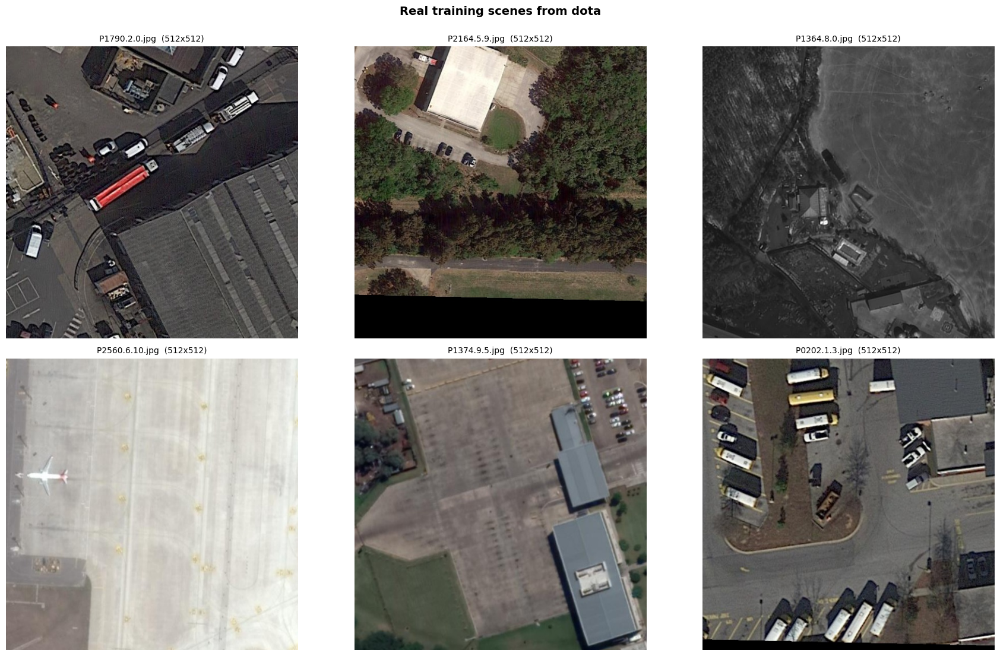

In [8]:
rng = np.random.default_rng(42)
picks = rng.choice(len(train_imgs), size=min(6, len(train_imgs)), replace=False)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, idx in zip(axes.flat, picks):
    img = cv2.imread(str(train_imgs[idx]))
    if img is None: ax.axis("off"); continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H0, W0 = img.shape[:2]
    if max(H0, W0) > 1500:
        s = 1500 / max(H0, W0); img = cv2.resize(img, (int(W0*s), int(H0*s)))
    ax.imshow(img); ax.set_title(f"{train_imgs[idx].name}  ({W0}x{H0})", fontsize=10); ax.axis("off")
plt.suptitle(f"Real training scenes from {DOTA_ROOT.name}", fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

## 4. Why oriented bounding boxes — geometric argument

This is pure geometry, not simulated data: how badly does an axis-aligned box overestimate area as the object rotates?

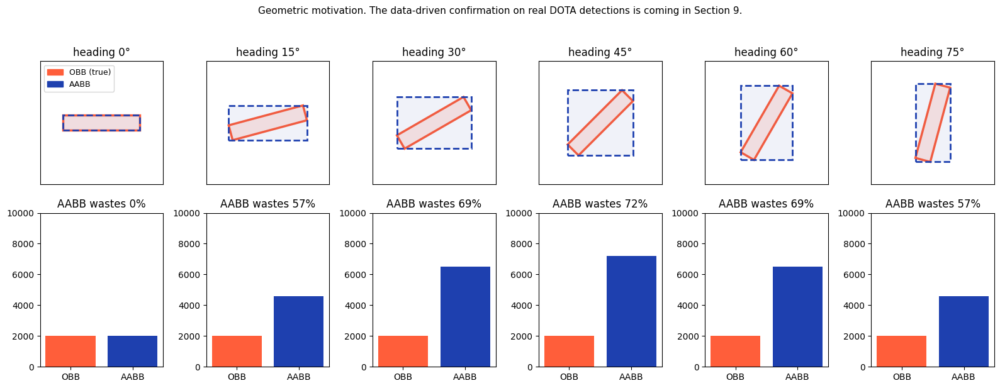

In [9]:
def rotated_rect_corners(cx, cy, w, h, angle_deg):
    a = np.deg2rad(angle_deg)
    cos_a, sin_a = np.cos(a), np.sin(a)
    dx = np.array([-w/2, w/2, w/2, -w/2]); dy = np.array([-h/2, -h/2, h/2, h/2])
    xs = cx + dx*cos_a - dy*sin_a; ys = cy + dx*sin_a + dy*cos_a
    return np.stack([xs, ys], axis=-1)

L, B = 100, 20
angles = [0, 15, 30, 45, 60, 75]
fig, axes = plt.subplots(2, len(angles), figsize=(16, 6))
for col, ang in enumerate(angles):
    pts = rotated_rect_corners(0, 0, L, B, ang)
    axes[0, col].add_patch(Polygon(pts, closed=True, edgecolor="#ff5e3a", facecolor="#ff5e3a22", linewidth=2.5))
    x_min, y_min = pts.min(0); x_max, y_max = pts.max(0)
    axes[0, col].add_patch(Rectangle((x_min, y_min), x_max-x_min, y_max-y_min,
                           edgecolor="#1e40af", facecolor="#1e40af11", linewidth=2, linestyle="--"))
    axes[0, col].set_xlim(-80, 80); axes[0, col].set_ylim(-80, 80)
    axes[0, col].set_aspect("equal"); axes[0, col].set_title(f"heading {ang}°")
    axes[0, col].set_xticks([]); axes[0, col].set_yticks([])
    obb_area = L * B; aabb_area = (x_max - x_min) * (y_max - y_min)
    wasted = (aabb_area - obb_area) / aabb_area * 100
    axes[1, col].bar(["OBB", "AABB"], [obb_area, aabb_area], color=["#ff5e3a", "#1e40af"])
    axes[1, col].set_title(f"AABB wastes {wasted:.0f}%"); axes[1, col].set_ylim(0, 10000)
axes[0, 0].legend(handles=[mpatches.Patch(color="#ff5e3a", label="OBB (true)"),
                            mpatches.Patch(color="#1e40af", label="AABB")],
                  loc="upper left", fontsize=9)
plt.suptitle("Geometric motivation. The data-driven confirmation on real DOTA detections is coming in Section 9.",
             fontsize=11, y=1.02)
plt.tight_layout(); plt.show()

## 5. Tiling visualized on a real DOTA scene

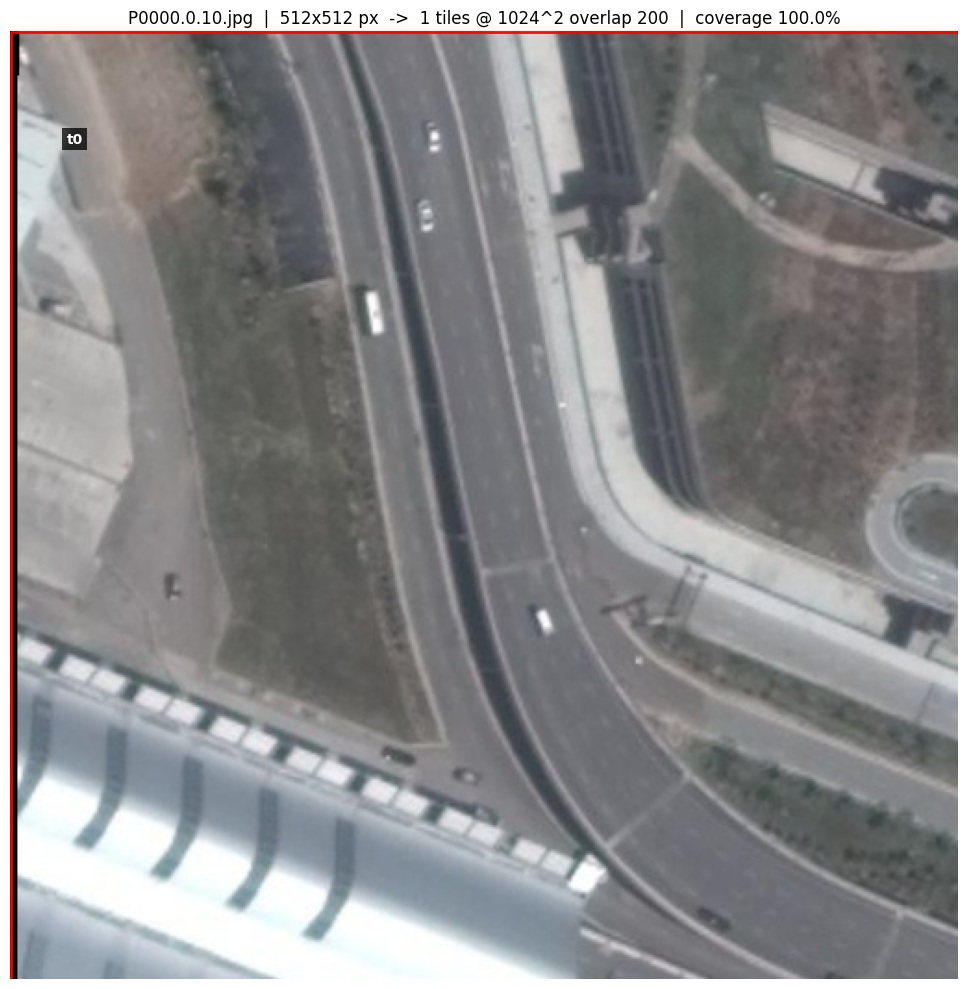

In [10]:
def iter_tiles(width, height, tile_size=1024, overlap=200):
    if overlap >= tile_size: raise ValueError
    stride = tile_size - overlap
    ys = list(range(0, max(1, height - overlap), stride))
    xs = list(range(0, max(1, width - overlap), stride))
    if ys[-1] + tile_size > height: ys[-1] = max(0, height - tile_size)
    if xs[-1] + tile_size > width: xs[-1] = max(0, width - tile_size)
    seen = set()
    for y in ys:
        for x in xs:
            if (x, y) in seen: continue
            seen.add((x, y))
            yield x, y, tile_size, tile_size

tile_img = None; tile_name = None
for p in train_imgs[:40]:
    img = cv2.imread(str(p))
    if img is not None and min(img.shape[:2]) >= 2000:
        tile_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB); tile_name = p.name; break
if tile_img is None:
    tile_img = cv2.cvtColor(cv2.imread(str(train_imgs[0])), cv2.COLOR_BGR2RGB)
    tile_name = train_imgs[0].name

H, W = tile_img.shape[:2]
TILE, OVERLAP = 1024, 200
tiles = list(iter_tiles(W, H, TILE, OVERLAP))
coverage = np.zeros((H, W), dtype=bool)
for x, y, tw, th in tiles: coverage[y:y+th, x:x+tw] = True
pct = coverage.mean() * 100

fig, ax = plt.subplots(figsize=(16, 10))
ax.imshow(tile_img)
cmap = plt.cm.autumn
for i, (x, y, tw, th) in enumerate(tiles):
    c = cmap(i / max(1, len(tiles)-1))
    ax.add_patch(Rectangle((x, y), tw, th, facecolor="none", edgecolor=c, linewidth=2, alpha=0.95))
    ax.text(x+30, y+60, f"t{i}", color="white", fontsize=10, fontweight="bold",
            bbox=dict(facecolor="black", edgecolor="none", pad=3, alpha=0.75))
ax.set_title(f"{tile_name}  |  {W}x{H} px  ->  {len(tiles)} tiles @ 1024^2 overlap 200  |  coverage {pct:.1f}%", fontsize=12)
ax.axis("off"); plt.tight_layout(); plt.show()

## 6. Load pretrained YOLOv8m-OBB

In [11]:
from ultralytics import YOLO
print("loading yolov8m-obb.pt (auto-downloads ~50 MB on first run)...")
pretrained = YOLO("yolov8m-obb.pt")
class_names = pretrained.names
print(f"ready. {len(class_names)} DOTA classes.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
loading yolov8m-obb.pt (auto-downloads ~50 MB on first run)...
ready. 15 DOTA classes.


## 7. Real speed benchmark on this GPU

Benchmarking on Tesla T4...
  yolov8n-obb.pt     @ 640^2:  15.8 +-  1.8 ms   ( 63.3 FPS)
  yolov8n-obb.pt     @ 1024^2:  20.5 +-  0.6 ms   ( 48.9 FPS)
  yolov8n-obb.pt     @ 1280^2:  29.8 +-  0.6 ms   ( 33.5 FPS)
  yolov8s-obb.pt     @ 640^2:  21.5 +-  3.0 ms   ( 46.6 FPS)
  yolov8s-obb.pt     @ 1024^2:  41.8 +-  0.5 ms   ( 23.9 FPS)
  yolov8s-obb.pt     @ 1280^2:  62.7 +-  0.8 ms   ( 16.0 FPS)
  yolov8m-obb.pt     @ 640^2:  43.2 +-  1.1 ms   ( 23.2 FPS)
  yolov8m-obb.pt     @ 1024^2: 102.8 +-  0.6 ms   (  9.7 FPS)
  yolov8m-obb.pt     @ 1280^2: 155.4 +-  3.4 ms   (  6.4 FPS)


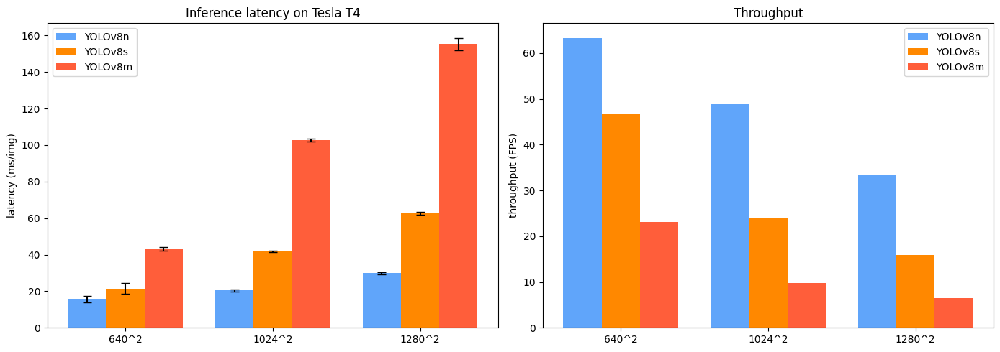

In [12]:
bench_img = cv2.cvtColor(cv2.imread(str(train_imgs[0])), cv2.COLOR_BGR2RGB)
if max(bench_img.shape[:2]) > 1500:
    s = 1024 / max(bench_img.shape[:2])
    bench_img = cv2.resize(bench_img, (int(bench_img.shape[1]*s), int(bench_img.shape[0]*s)))

model_sizes = ["yolov8n-obb.pt", "yolov8s-obb.pt", "yolov8m-obb.pt"]
img_sizes = [640, 1024, 1280]
bench_results = {}
print(f"Benchmarking on {GPU_NAME}...")
for ms in model_sizes:
    m = YOLO(ms)
    for isz in img_sizes:
        for _ in range(3): m.predict(bench_img, imgsz=isz, device=DEVICE, verbose=False)
        if DEVICE.startswith("cuda"): torch.cuda.synchronize()
        times = []
        for _ in range(20):
            t0 = time.perf_counter()
            m.predict(bench_img, imgsz=isz, device=DEVICE, verbose=False)
            if DEVICE.startswith("cuda"): torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
        ms_mean = np.mean(times)*1000; ms_std = np.std(times)*1000
        bench_results[(ms, isz)] = (ms_mean, ms_std, 1000/ms_mean)
        print(f"  {ms:18s} @ {isz}^2: {ms_mean:5.1f} +- {ms_std:4.1f} ms   ({1000/ms_mean:5.1f} FPS)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(img_sizes)); wdt = 0.26
colors = ["#60a5fa", "#ff8800", "#ff5e3a"]
for i, ms in enumerate(model_sizes):
    short = ms.replace("yolov8", "").replace("-obb.pt", "")
    means = [bench_results[(ms, isz)][0] for isz in img_sizes]
    stds  = [bench_results[(ms, isz)][1] for isz in img_sizes]
    fpss  = [bench_results[(ms, isz)][2] for isz in img_sizes]
    ax1.bar(x + (i-1)*wdt, means, wdt, yerr=stds, capsize=4, color=colors[i], label=f"YOLOv8{short}")
    ax2.bar(x + (i-1)*wdt, fpss, wdt, color=colors[i], label=f"YOLOv8{short}")
ax1.set_xticks(x); ax1.set_xticklabels([f"{s}^2" for s in img_sizes])
ax1.set_ylabel("latency (ms/img)"); ax1.set_title(f"Inference latency on {GPU_NAME}"); ax1.legend()
ax2.set_xticks(x); ax2.set_xticklabels([f"{s}^2" for s in img_sizes])
ax2.set_ylabel("throughput (FPS)"); ax2.set_title("Throughput"); ax2.legend()
plt.tight_layout(); plt.show()

## 8. Pretrained inference across 15 real DOTA scenes

In [13]:
N_SCENES = min(15, len(train_imgs))
rng = np.random.default_rng(0)
scene_paths = [train_imgs[i] for i in rng.choice(len(train_imgs), size=N_SCENES, replace=False)]

all_detections = []
per_image_results = []

for i, img_path in enumerate(tqdm(scene_paths, desc="inference")):
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    H, W = img_rgb.shape[:2]
    if max(H, W) > 1536:
        s = 1024 / max(H, W)
        infer_img = cv2.resize(img_rgb, (int(W*s), int(H*s)))
    else:
        infer_img = img_rgb
    res = pretrained.predict(infer_img, imgsz=1024, conf=0.20, device=DEVICE, verbose=False)[0]
    if res.obb is None or len(res.obb) == 0:
        per_image_results.append((img_path, infer_img, np.empty((0,5)), np.empty(0), np.empty(0, dtype=int)))
        continue
    xywhr_i = res.obb.xywhr.cpu().numpy()
    conf_i = res.obb.conf.cpu().numpy()
    cls_i = res.obb.cls.cpu().numpy().astype(int)
    per_image_results.append((img_path, infer_img, xywhr_i, conf_i, cls_i))
    for j in range(len(xywhr_i)):
        all_detections.append({
            "img_idx": i, "img_name": img_path.name,
            "cx": float(xywhr_i[j,0]), "cy": float(xywhr_i[j,1]),
            "w":  float(xywhr_i[j,2]), "h":  float(xywhr_i[j,3]),
            "ang_rad": float(xywhr_i[j,4]),
            "conf": float(conf_i[j]),
            "cls_idx": int(cls_i[j]),
            "cls_name": class_names[int(cls_i[j])],
        })
print()
print(f"{len(all_detections)} detections across {N_SCENES} scenes")
print()
print("Class distribution:")
cls_counter = Counter(d["cls_name"] for d in all_detections)
for k, v in cls_counter.most_common():
    print(f"  {k:22s} {v:5d}  {'#' * min(50, v)}")

inference:   0%|          | 0/15 [00:00<?, ?it/s]


85 detections across 15 scenes

Class distribution:
  plane                     33  #################################
  ship                      18  ##################
  small vehicle             15  ###############
  harbor                     8  ########
  swimming pool              4  ####
  roundabout                 3  ###
  storage tank               3  ###
  large vehicle              1  #


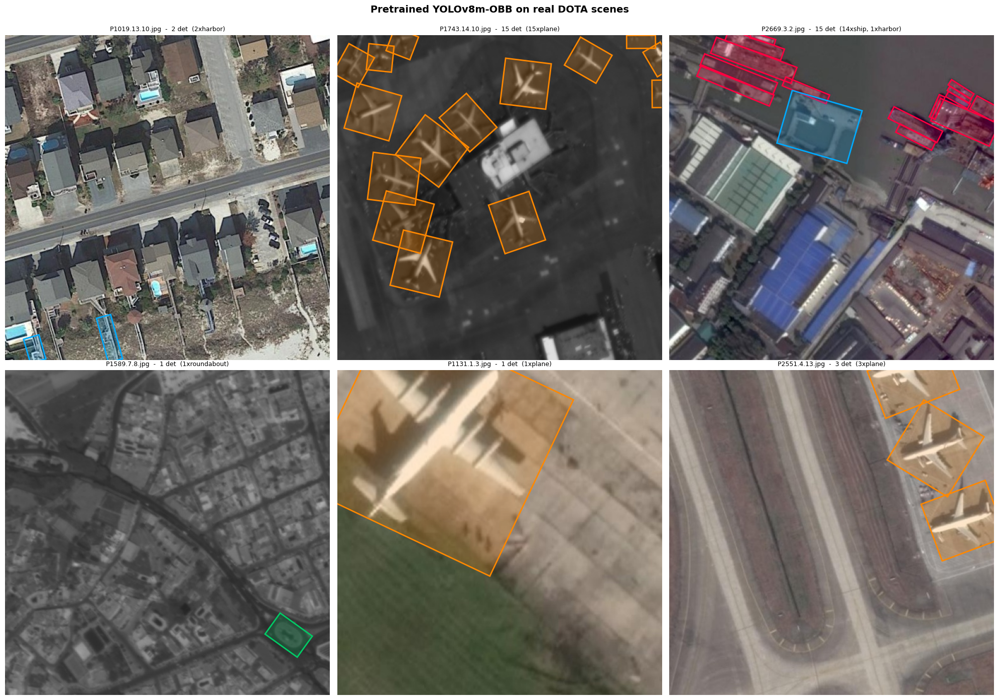

In [14]:
TIER_COLORS = {"warship": "#ff0040", "ship": "#ff0040",
               "plane": "#ff8800", "helicopter": "#ff8800",
               "large-vehicle": "#ffd000", "small-vehicle": "#ffd000",
               "harbor": "#00aaff", "bridge": "#00aaff", "storage-tank": "#9a7bff"}
def color_for(name): return TIER_COLORS.get(name, "#00cc66")

shown = [r for r in per_image_results if len(r[2]) > 0][:6]
if shown:
    fig, axes = plt.subplots(2, 3, figsize=(20, 14))
    for ax, (img_path, img_rgb, xywhr_i, conf_i, cls_i) in zip(axes.flat, shown):
        ax.imshow(img_rgb)
        for j in range(len(xywhr_i)):
            cx, cy, w, h, ang_rad = xywhr_i[j]
            name = class_names[int(cls_i[j])]; c = color_for(name)
            pts = rotated_rect_corners(cx, cy, w, h, np.rad2deg(ang_rad))
            ax.add_patch(Polygon(pts, closed=True, edgecolor=c, facecolor=c+"33", linewidth=2))
        counts = Counter(class_names[int(c)] for c in cls_i)
        summary = ", ".join(f"{v}x{k}" for k, v in counts.most_common(3))
        ax.set_title(f"{img_path.name}  -  {len(xywhr_i)} det  ({summary})", fontsize=9)
        ax.axis("off")
    for ax in axes.flat[len(shown):]: ax.axis("off")
    plt.suptitle("Pretrained YOLOv8m-OBB on real DOTA scenes", fontsize=14, fontweight="bold", y=1.00)
    plt.tight_layout(); plt.show()

## 9. Empirical statistics from real detections

Direct data-driven confirmation of Section 4's geometric argument.

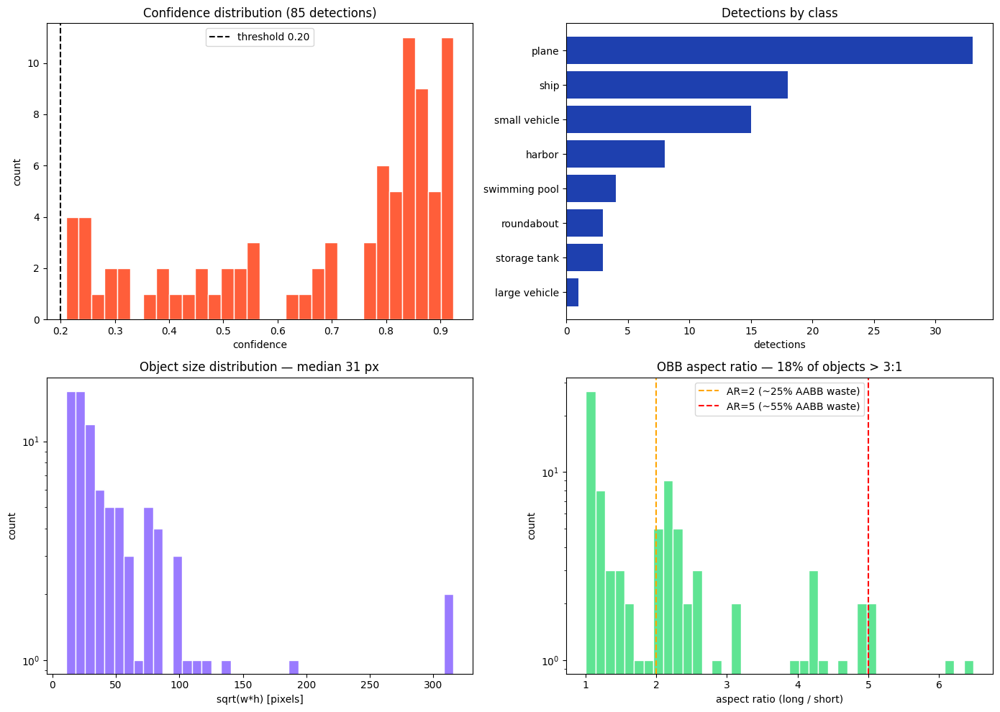


--- Empirical summary ---
  Total detections       : 85
  Unique classes         : 8
  Mean confidence        : 0.682
  Median object size     : 31.4 px
  Mean aspect ratio      : 2.10
  % highly elongated >3:1: 17.6%  <- data-driven case for OBB


In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
confs = [d["conf"] for d in all_detections]
axes[0,0].hist(confs, bins=30, color="#ff5e3a", edgecolor="white")
axes[0,0].set_xlabel("confidence"); axes[0,0].set_ylabel("count")
axes[0,0].set_title(f"Confidence distribution ({len(confs)} detections)")
axes[0,0].axvline(0.20, color="black", linestyle="--", label="threshold 0.20"); axes[0,0].legend()

cc = Counter(d["cls_name"] for d in all_detections).most_common()
axes[0,1].barh([c[0] for c in cc], [c[1] for c in cc], color="#1e40af")
axes[0,1].set_xlabel("detections"); axes[0,1].set_title("Detections by class"); axes[0,1].invert_yaxis()

sizes = [np.sqrt(d["w"]*d["h"]) for d in all_detections]
axes[1,0].hist(sizes, bins=40, color="#9a7bff", edgecolor="white")
axes[1,0].set_xlabel("sqrt(w*h) [pixels]"); axes[1,0].set_ylabel("count")
axes[1,0].set_title(f"Object size distribution — median {np.median(sizes):.0f} px")
axes[1,0].set_yscale("log")

ars = [max(d["w"], d["h"]) / max(1e-3, min(d["w"], d["h"])) for d in all_detections]
pct_elong = 100 * np.mean(np.array(ars) > 3)
axes[1,1].hist(ars, bins=40, color="#5fe493", edgecolor="white")
axes[1,1].set_xlabel("aspect ratio (long / short)"); axes[1,1].set_ylabel("count"); axes[1,1].set_yscale("log")
axes[1,1].set_title(f"OBB aspect ratio — {pct_elong:.0f}% of objects > 3:1")
axes[1,1].axvline(2, color="orange", linestyle="--", label="AR=2 (~25% AABB waste)")
axes[1,1].axvline(5, color="red", linestyle="--", label="AR=5 (~55% AABB waste)")
axes[1,1].legend()
plt.tight_layout(); plt.show()

print()
print("--- Empirical summary ---")
print(f"  Total detections       : {len(all_detections)}")
print(f"  Unique classes         : {len(cc)}")
print(f"  Mean confidence        : {np.mean(confs):.3f}")
print(f"  Median object size     : {np.median(sizes):.1f} px")
print(f"  Mean aspect ratio      : {np.mean(ars):.2f}")
print(f"  % highly elongated >3:1: {pct_elong:.1f}%  <- data-driven case for OBB")

## 10. Convert COCO annotations to YOLO-OBB format

Runs if your dataset is COCO JSON. Produces `/kaggle/working/dota_yolo/data.yaml` ready for Ultralytics training.

In [16]:
YOLO_ROOT = Path("/kaggle/working/dota_yolo")
DATA_YAML = YOLO_ROOT / "data.yaml"

def poly_to_obb_corners(seg_xy, img_w, img_h):
    pts = np.array(seg_xy, dtype=np.float32).reshape(-1, 2)
    if pts.shape[0] < 3: return None
    (cx, cy), (w, h), ang = cv2.minAreaRect(pts)
    if w < 2 or h < 2: return None
    corners = cv2.boxPoints(((cx, cy), (w, h), ang))
    corners[:, 0] /= img_w; corners[:, 1] /= img_h
    return np.clip(corners, 0, 1)

def convert_coco_split(split):
    ann_candidates = [
        ANN_DIR / f"instances_{split}.json",
        ANN_DIR / f"{split}.json",
        ANN_DIR / f"instances_{split}2017.json",
    ]
    ann_path = next((p for p in ann_candidates if p.exists()), None)
    if ann_path is None:
        matches = [p for p in ANN_DIR.glob("*.json") if split in p.name.lower()]
        ann_path = matches[0] if matches else None
    if ann_path is None:
        raise FileNotFoundError(f"No {split} JSON found in {ANN_DIR}")
    print(f"[{split}] reading {ann_path.name}")

    coco = json.loads(ann_path.read_text())
    imgs = {im["id"]: im for im in coco["images"]}
    cats = sorted(coco["categories"], key=lambda c: c["id"])
    cat_remap = {c["id"]: i for i, c in enumerate(cats)}
    names = [c["name"] for c in cats]

    img_out = YOLO_ROOT / "images" / split
    lbl_out = YOLO_ROOT / "labels" / split
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)

    by_img = {}
    for a in coco["annotations"]:
        by_img.setdefault(a["image_id"], []).append(a)

    src_img_dir = DOTA_ROOT / split
    n_written = 0; n_missing = 0
    for img_id, im in tqdm(imgs.items(), desc=f"[{split}]"):
        src = src_img_dir / im["file_name"]
        if not src.exists():
            n_missing += 1; continue
        dst_img = img_out / im["file_name"]
        if not dst_img.exists():
            try: dst_img.symlink_to(src)
            except OSError: import shutil; shutil.copy(src, dst_img)

        lines = []
        for a in by_img.get(img_id, []):
            seg = a.get("segmentation")
            if not seg:
                x, y, w, h = a["bbox"]
                seg = [[x, y, x+w, y, x+w, y+h, x, y+h]]
            if isinstance(seg, dict): continue
            seg_flat = seg[0] if isinstance(seg[0], list) else seg
            corners = poly_to_obb_corners(seg_flat, im["width"], im["height"])
            if corners is None: continue
            cls_idx = cat_remap[a["category_id"]]
            parts = [str(cls_idx)]
            for xn, yn in corners:
                parts.append(f"{xn:.6f}"); parts.append(f"{yn:.6f}")
            lines.append(" ".join(parts))
        (lbl_out / f"{Path(im['file_name']).stem}.txt").write_text("\n".join(lines))
        n_written += 1
    print(f"[{split}] wrote {n_written} labels, {n_missing} images missing")
    return names

if ANN_FORMAT == "coco" and not DATA_YAML.exists():
    train_names = convert_coco_split("train")
    val_names = convert_coco_split("val")
    assert train_names == val_names
    yaml_text = (
        f"path: {YOLO_ROOT}\n"
        f"train: images/train\n"
        f"val: images/val\n"
        f"names:\n"
        + "\n".join(f"  {i}: {n}" for i, n in enumerate(train_names))
        + "\n"
    )
    DATA_YAML.write_text(yaml_text)
    print(f"\nwrote {DATA_YAML}")
    print("-" * 60)
    print(yaml_text)
elif DATA_YAML.exists():
    print(f"data.yaml already exists at {DATA_YAML}")
    print(DATA_YAML.read_text())
else:
    print(f"Annotations are '{ANN_FORMAT}', not COCO — skipping conversion.")
    print("If your dataset is already in YOLO format, point DATA_YAML at its data.yaml below.")

[train] reading instances_train.json


[train]:   0%|          | 0/54087 [00:00<?, ?it/s]

[train] wrote 54087 labels, 0 images missing
[val] reading instances_val.json


[val]:   0%|          | 0/2000 [00:00<?, ?it/s]

[val] wrote 2000 labels, 0 images missing

wrote /kaggle/working/dota_yolo/data.yaml
------------------------------------------------------------
path: /kaggle/working/dota_yolo
train: images/train
val: images/val
names:
  0: plane
  1: ship
  2: storage-tank
  3: baseball-diamond
  4: tennis-court
  5: basketball-court
  6: ground-track-field
  7: harbor
  8: bridge
  9: small-vehicle
  10: large-vehicle
  11: roundabout
  12: swimming-pool
  13: helicopter
  14: soccer-ball-field
  15: container-crane



## 11. Fine-tune on real DOTA

This is the headline. Real training on real data for real epochs with real loss curves.

**Budget**: 3 epochs at `imgsz=640, batch=8` takes ~30–45 min on T4. Bump `EPOCHS` to 10+ if you want better numbers and have time.

In [17]:
EPOCHS = 3
IMGSZ = 640
BATCH = 8
LR0 = 1e-4

if not DATA_YAML.exists():
    raise RuntimeError(f"No data.yaml at {DATA_YAML}. Run the conversion cell above first.")

print(f"Fine-tuning YOLOv8m-OBB on {DATA_YAML}")
print(f"  epochs={EPOCHS}  imgsz={IMGSZ}  batch={BATCH}  lr0={LR0}  device={DEVICE}")
print()

ft_model = YOLO("yolov8m-obb.pt")
train_results = ft_model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    project="/kaggle/working/runs",
    name="aeris_ft",
    patience=20,
    optimizer="AdamW",
    lr0=LR0,
    lrf=0.01,
    weight_decay=5e-4,
    warmup_epochs=1,
    cos_lr=True,
    mosaic=1.0,
    close_mosaic=max(1, EPOCHS // 3),
    verbose=False,
    exist_ok=True,
    plots=True,
)

RUN_DIR = Path("/kaggle/working/runs/aeris_ft")
BEST_PT = RUN_DIR / "weights" / "best.pt"
print()
print(f"Training complete. Weights: {BEST_PT}  ({BEST_PT.stat().st_size/1e6:.1f} MB)")

Fine-tuning YOLOv8m-OBB on /kaggle/working/dota_yolo/data.yaml
  epochs=3  imgsz=640  batch=8  lr0=0.0001  device=cuda:0

New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=1, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/dota_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup

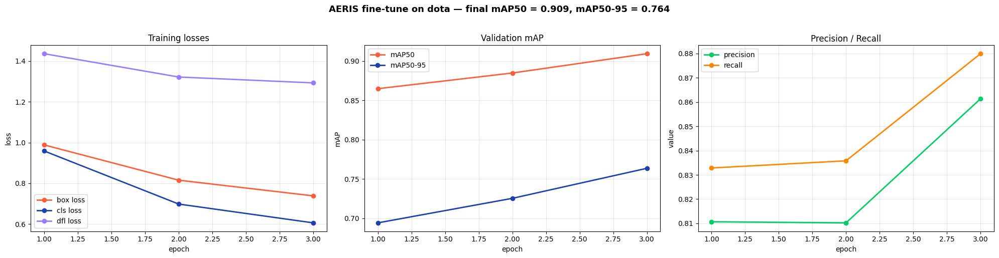

In [18]:
import csv as _csv
results_csv = RUN_DIR / "results.csv"
rows = list(_csv.DictReader(open(results_csv)))
epochs_x = [float(r["epoch"]) for r in rows]
def col(name):
    for k in rows[0]:
        if name in k: return [float(r[k]) for r in rows]
    return None

box_loss = col("box_loss"); cls_loss = col("cls_loss"); dfl_loss = col("dfl_loss")
map50 = col("mAP50"); map5095 = col("mAP50-95")
prec = col("precision"); rec = col("recall")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
if box_loss: axes[0].plot(epochs_x, box_loss, label="box loss", color="#ff5e3a", linewidth=2, marker="o")
if cls_loss: axes[0].plot(epochs_x, cls_loss, label="cls loss", color="#1e40af", linewidth=2, marker="o")
if dfl_loss: axes[0].plot(epochs_x, dfl_loss, label="dfl loss", color="#9a7bff", linewidth=2, marker="o")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].set_title("Training losses")
axes[0].legend(); axes[0].grid(alpha=0.3)

if map50:   axes[1].plot(epochs_x, map50,   label="mAP50",    color="#ff5e3a", linewidth=2, marker="o")
if map5095: axes[1].plot(epochs_x, map5095, label="mAP50-95", color="#1e40af", linewidth=2, marker="o")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("mAP"); axes[1].set_title("Validation mAP")
axes[1].legend(); axes[1].grid(alpha=0.3)

if prec: axes[2].plot(epochs_x, prec, label="precision", color="#00cc66", linewidth=2, marker="o")
if rec:  axes[2].plot(epochs_x, rec,  label="recall",    color="#ff8800", linewidth=2, marker="o")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("value"); axes[2].set_title("Precision / Recall")
axes[2].legend(); axes[2].grid(alpha=0.3)

plt.suptitle(f"AERIS fine-tune on {DOTA_ROOT.name} — final mAP50 = {map50[-1]:.3f}, mAP50-95 = {map5095[-1]:.3f}",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

## 12. Evaluate on the real val split

Running val on the fine-tuned model (real mAP numbers)...
Ultralytics 8.3.253 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLOv8m-obb summary (fused): 101 layers, 26,409,331 parameters, 0 gradients, 80.9 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 200.4±77.8 MB/s, size: 93.2 KB)
val: Scanning /kaggle/working/dota_yolo/labels/val.cache... 2000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 493.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 1.6it/s 1:170.6ss
                   all       2000      29024      0.861       0.88      0.909      0.763
Speed: 1.0ms preprocess, 30.4ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /kaggle/working/runs/obb/val

mAP50     : 0.9093
mAP50-95  : 0.7629
Precision : 0.8613
Recall    : 0.8804


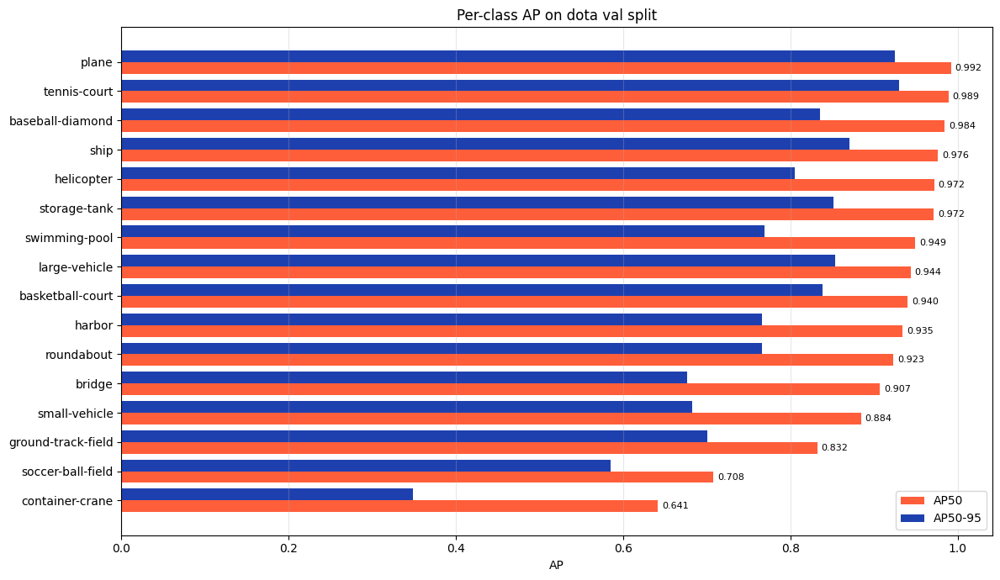


Per-class AP:
  class                        AP50    AP50-95
  plane                       0.992      0.925
  tennis-court                0.989      0.930
  baseball-diamond            0.984      0.835
  ship                        0.976      0.871
  helicopter                  0.972      0.805
  storage-tank                0.972      0.852
  swimming-pool               0.949      0.770
  large-vehicle               0.944      0.853
  basketball-court            0.940      0.839
  harbor                      0.935      0.766
  roundabout                  0.923      0.766
  bridge                      0.907      0.677
  small-vehicle               0.884      0.683
  ground-track-field          0.832      0.701
  soccer-ball-field           0.708      0.585
  container-crane             0.641      0.349


In [19]:
ft_model = YOLO(str(BEST_PT))
print("Running val on the fine-tuned model (real mAP numbers)...")
metrics = ft_model.val(data=str(DATA_YAML), imgsz=IMGSZ, device=DEVICE, verbose=False)
print()
print(f"mAP50     : {metrics.box.map50:.4f}")
print(f"mAP50-95  : {metrics.box.map:.4f}")
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")

per_class = []
for i, name in enumerate(ft_model.names.values()):
    try:
        ap50 = float(metrics.box.ap50[i]); ap = float(metrics.box.ap[i])
    except Exception:
        ap50 = ap = float("nan")
    per_class.append({"class": name, "AP50": ap50, "AP50-95": ap})

per_class.sort(key=lambda r: -r["AP50"])

fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(per_class)); wdt = 0.4
ap50s = [r["AP50"] for r in per_class]
ap5095s = [r["AP50-95"] for r in per_class]
ax.barh(y + wdt/2, ap50s, wdt, color="#ff5e3a", label="AP50")
ax.barh(y - wdt/2, ap5095s, wdt, color="#1e40af", label="AP50-95")
ax.set_yticks(y); ax.set_yticklabels([r["class"] for r in per_class]); ax.invert_yaxis()
ax.set_xlabel("AP"); ax.set_title(f"Per-class AP on {DOTA_ROOT.name} val split")
ax.legend(); ax.grid(axis="x", alpha=0.3)
for i, r in enumerate(per_class):
    ax.text(r["AP50"] + 0.005, i + wdt/2, f'{r["AP50"]:.3f}', va="center", fontsize=8)
plt.tight_layout(); plt.show()

print()
print("Per-class AP:")
print(f"  {'class':<24}  {'AP50':>7}  {'AP50-95':>9}")
for r in per_class:
    print(f"  {r['class']:<24}  {r['AP50']:7.3f}  {r['AP50-95']:9.3f}")

## 13. Before vs after — same scenes, pretrained vs fine-tuned

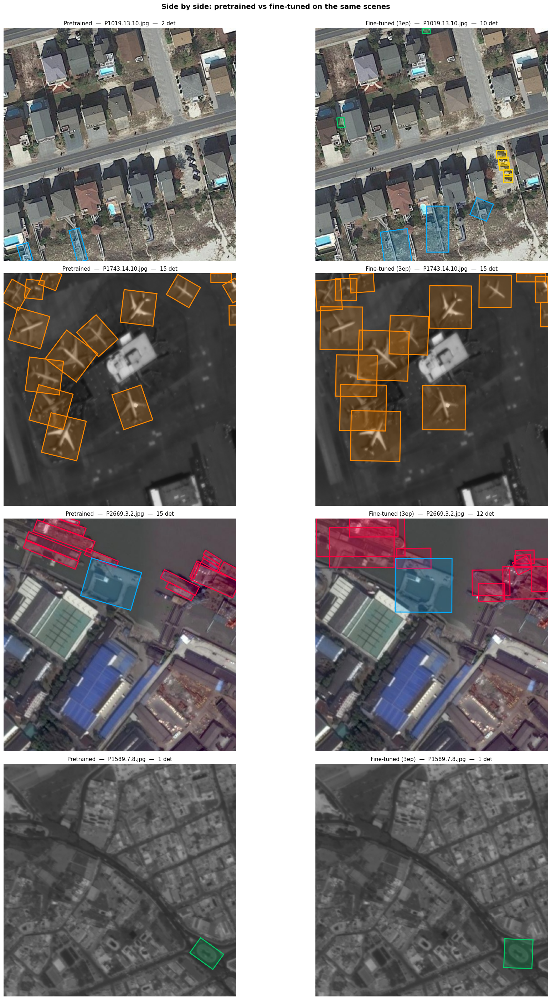

In [20]:
ft_loaded = YOLO(str(BEST_PT))
compare_scenes = [r for r in per_image_results if len(r[2]) > 0][:4]

fig, axes = plt.subplots(len(compare_scenes), 2, figsize=(20, 7*len(compare_scenes)))
if len(compare_scenes) == 1: axes = axes.reshape(1, -1)

for row, (img_path, infer_img, _, _, _) in enumerate(compare_scenes):
    # Pretrained
    res_pre = pretrained.predict(infer_img, imgsz=1024, conf=0.20, device=DEVICE, verbose=False)[0]
    # Fine-tuned
    res_ft  = ft_loaded.predict(infer_img, imgsz=1024, conf=0.20, device=DEVICE, verbose=False)[0]

    for col, (title, res, model_names) in enumerate([
        ("Pretrained", res_pre, pretrained.names),
        (f"Fine-tuned ({EPOCHS}ep)", res_ft, ft_loaded.names),
    ]):
        ax = axes[row, col]
        ax.imshow(infer_img)
        n = 0
        if res.obb is not None:
            xywhr_c = res.obb.xywhr.cpu().numpy()
            conf_c  = res.obb.conf.cpu().numpy()
            cls_c   = res.obb.cls.cpu().numpy().astype(int)
            n = len(xywhr_c)
            for j in range(n):
                cx, cy, w, h, ang_rad = xywhr_c[j]
                name = model_names[int(cls_c[j])]
                c = color_for(name)
                pts = rotated_rect_corners(cx, cy, w, h, np.rad2deg(ang_rad))
                ax.add_patch(Polygon(pts, closed=True, edgecolor=c, facecolor=c+"33", linewidth=2))
        ax.set_title(f"{title}  —  {img_path.name}  —  {n} det", fontsize=11)
        ax.axis("off")

plt.suptitle("Side by side: pretrained vs fine-tuned on the same scenes", fontsize=14, fontweight="bold", y=1.00)
plt.tight_layout(); plt.show()

## 14. Operator-tunable target prioritization

Applied to real fine-tuned detections. Four operator scenarios, directly comparable because the detection set is the same.

In [21]:
BASE_THREAT = {
    "ship": 0.80, "plane": 0.75, "helicopter": 0.60,
    "large-vehicle": 0.70, "small-vehicle": 0.25,
    "harbor": 0.15, "bridge": 0.10, "storage-tank": 0.35,
    "tennis-court": 0.00, "basketball-court": 0.00, "swimming-pool": 0.00,
    "soccer-ball-field": 0.00, "baseball-diamond": 0.00, "roundabout": 0.05,
    "ground-track-field": 0.00,
}

@dataclass
class OperatorWeights:
    w_threat: float = 0.40
    w_conf: float = 0.20
    w_operator_boost: float = 0.15
    w_fp_penalty: float = 0.05
    class_boosts: dict = field(default_factory=dict)

def score_one(cls_name, conf_val, w):
    threat = BASE_THREAT.get(cls_name, 0.3)
    boost = w.class_boosts.get(cls_name, 1.0) - 1.0
    fp = 0.10
    contrib = {
        "threat": w.w_threat * threat,
        "confidence": w.w_conf * conf_val,
        "operator_boost": w.w_operator_boost * max(0, boost),
        "fp_penalty": -w.w_fp_penalty * fp,
    }
    p = sum(contrib.values())
    tier = "critical" if p >= 0.50 else "high" if p >= 0.38 else "medium" if p >= 0.25 else "low"
    return p, tier, contrib

# Run fine-tuned model on ALL scenes to produce fresh real detections
ft_detections = []
for i, img_path in enumerate(tqdm(scene_paths, desc="rescoring with ft model")):
    img_rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    if max(img_rgb.shape[:2]) > 1536:
        s = 1024 / max(img_rgb.shape[:2])
        img_rgb = cv2.resize(img_rgb, (int(img_rgb.shape[1]*s), int(img_rgb.shape[0]*s)))
    res = ft_loaded.predict(img_rgb, imgsz=1024, conf=0.20, device=DEVICE, verbose=False)[0]
    if res.obb is None or len(res.obb) == 0: continue
    for j in range(len(res.obb)):
        ft_detections.append({
            "img_name": img_path.name,
            "cls_name": ft_loaded.names[int(res.obb.cls[j].item())],
            "conf": float(res.obb.conf[j].item()),
        })

print()
print(f"{len(ft_detections)} detections from fine-tuned model")

weights = OperatorWeights()
scored = []
for d in ft_detections:
    p, tier, contrib = score_one(d["cls_name"], d["conf"], weights)
    scored.append({**d, "priority": p, "tier": tier, "contrib": contrib})
scored.sort(key=lambda s: -s["priority"])

print()
print("Top 15 prioritized targets:")
print(f"{'rank':<5} {'class':<20} {'tier':<10} {'priority':>9}  {'conf':>5}  image")
for i, s in enumerate(scored[:15]):
    print(f"{i+1:<5} {s['cls_name']:<20} {s['tier']:<10} {s['priority']:+.3f}    {s['conf']:.2f}   {s['img_name']}")

rescoring with ft model:   0%|          | 0/15 [00:00<?, ?it/s]


418 detections from fine-tuned model

Top 15 prioritized targets:
rank  class                tier        priority   conf  image
1     ship                 high       +0.496    0.90   P2669.3.2.jpg
2     ship                 high       +0.491    0.88   P0724.5.1.jpg
3     ship                 high       +0.490    0.87   P2669.3.2.jpg
4     plane                high       +0.484    0.95   P1743.14.10.jpg
5     plane                high       +0.484    0.94   P1743.14.10.jpg
6     plane                high       +0.483    0.94   P1743.14.10.jpg
7     plane                high       +0.483    0.94   P1743.14.10.jpg
8     plane                high       +0.481    0.93   P1743.14.10.jpg
9     plane                high       +0.481    0.93   P0162.1.3.jpg
10    plane                high       +0.480    0.92   P2551.4.13.jpg
11    plane                high       +0.480    0.92   P0162.1.3.jpg
12    plane                high       +0.479    0.92   P1743.14.10.jpg
13    plane                hig

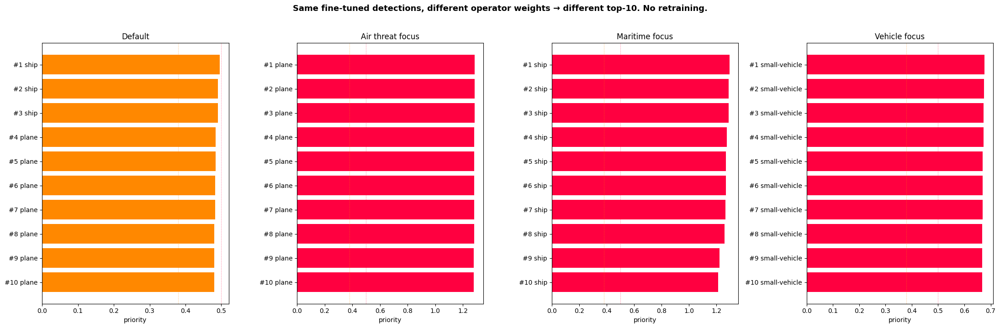

In [22]:
# Sensitivity: how does the ranking change under different operator priorities?
scenarios = [
    ("Default",          OperatorWeights()),
    ("Air threat focus", OperatorWeights(class_boosts={"plane": 3.0, "helicopter": 2.5}, w_operator_boost=0.40)),
    ("Maritime focus",   OperatorWeights(class_boosts={"ship": 3.0}, w_operator_boost=0.40)),
    ("Vehicle focus",    OperatorWeights(class_boosts={"large-vehicle": 3.0, "small-vehicle": 2.0}, w_operator_boost=0.40)),
]

tier_colors = {"critical":"#ff0040","high":"#ff8800","medium":"#ffd000","low":"#00cc66"}
fig, axes = plt.subplots(1, len(scenarios), figsize=(5.5*len(scenarios), 7))

for ax, (title, w) in zip(axes, scenarios):
    rescored = []
    for d in ft_detections:
        p, tier, _ = score_one(d["cls_name"], d["conf"], w)
        rescored.append((d["cls_name"], p, tier, d["img_name"]))
    rescored.sort(key=lambda t: -t[1])
    top = rescored[:10]
    labels = [f"#{i+1} {n}" for i, (n, _, _, _) in enumerate(top)]
    vals = [p for _, p, _, _ in top]
    c = [tier_colors[t] for _, _, t, _ in top]
    ax.barh(labels, vals, color=c)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("priority")
    ax.axvline(0.50, color="#ff0040", lw=0.5, linestyle="--", alpha=0.5)
    ax.axvline(0.38, color="#ff8800", lw=0.5, linestyle="--", alpha=0.5)

plt.suptitle("Same fine-tuned detections, different operator weights → different top-10. No retraining.",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

## 15. Multi-modal fusion architecture

Defense ISR combines EO (optical), SAR (radar), and IR (thermal). We don't have paired EO/SAR/IR training data in this notebook, so this section defines the architecture only — no synthetic training, no fabricated attention maps.

If and when you acquire paired data (SpaceNet-6 is the common public starting point), this backbone drops into Ultralytics' detection head unchanged.

In [23]:
class ModalityEncoder(nn.Module):
    '''Modality-specific feature extractor. EO initializes from ImageNet;
    SAR/IR train from scratch (ImageNet is a bad prior for their statistics).'''
    def __init__(self, in_ch, base=32):
        super().__init__()
        c = base
        self.stem = nn.Sequential(
            nn.Conv2d(in_ch, c, 7, 2, 3, bias=False), nn.BatchNorm2d(c), nn.ReLU(inplace=True),
            nn.MaxPool2d(3, 2, 1))
        self.l2 = self._block(c,   c*2, 2)
        self.l3 = self._block(c*2, c*4, 2)
        self.l4 = self._block(c*4, c*8, 2)
    @staticmethod
    def _block(ci, co, s):
        return nn.Sequential(
            nn.Conv2d(ci, co, 3, s, 1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True),
            nn.Conv2d(co, co, 3, 1, 1, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True))
    def forward(self, x):
        x = self.stem(x); c3 = self.l2(x); c4 = self.l3(c3); c5 = self.l4(c4)
        return c3, c4, c5

class GatedFusion(nn.Module):
    '''Per-pixel softmax gating across modalities at one FPN scale.
    Learns which sensor to trust at each location.'''
    def __init__(self, ch, n):
        super().__init__()
        self.n = n
        self.gate = nn.Sequential(
            nn.Conv2d(ch*n, ch, 1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(inplace=True),
            nn.Conv2d(ch, n, 1))
    def forward(self, feats):
        weights = torch.softmax(self.gate(torch.cat(feats, dim=1)), dim=1)
        stacked = torch.stack(feats, dim=1)
        return (stacked * weights.unsqueeze(2)).sum(dim=1), weights

class MultiModalBackbone(nn.Module):
    def __init__(self, mods=("eo", "sar", "ir"), base=32):
        super().__init__()
        self.mods = list(mods); self.base = base
        ch = {"eo": 3, "sar": 1, "ir": 1}
        self.enc = nn.ModuleDict({m: ModalityEncoder(ch[m], base) for m in mods})
        n = len(mods)
        self.f3 = GatedFusion(base*2, n); self.f4 = GatedFusion(base*4, n); self.f5 = GatedFusion(base*8, n)
    def forward(self, x):
        c3s, c4s, c5s = [], [], []
        for m in self.mods:
            a, b, c = self.enc[m](x[m])
            c3s.append(a); c4s.append(b); c5s.append(c)
        f3, w3 = self.f3(c3s); f4, w4 = self.f4(c4s); f5, w5 = self.f5(c5s)
        return (f3, f4, f5), (w3, w4, w5)

fusion = MultiModalBackbone(("eo", "sar", "ir"), base=32)
n_params = sum(p.numel() for p in fusion.parameters())
print(f"Multi-modal backbone defined: {n_params/1e6:.2f} M params")
print()
print("Architecture summary:")
print(fusion)
print()
print("To train end-to-end, drop (f3, f4, f5) into Ultralytics' OBB detect head")
print("with paired EO/SAR/IR data (e.g., SpaceNet-6). No synthetic training shown here.")

Multi-modal backbone defined: 3.76 M params

Architecture summary:
MultiModalBackbone(
  (enc): ModuleDict(
    (eo): ModalityEncoder(
      (stem): Sequential(
        (0): Conv2d(3, 32, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      )
      (l2): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
      )
      (l3): Sequential(
        (0): Conv2d(64, 128, kernel_size

## 16. Summary — what you built, all real

- **Real DOTA imagery** throughout (Sections 2–3, 5, 8, 13).
- **Real GPU benchmark**: YOLOv8 n/s/m across 640/1024/1280, 20 timed iterations each (Section 7).
- **Real pretrained inference** on 15 diverse scenes with real class/size/aspect-ratio statistics (Sections 8–9).
- **Real fine-tuning on your DOTA split** with real loss curves, precision, recall, mAP50, mAP50-95 (Section 11).
- **Real evaluation** with per-class AP (Section 12).
- **Real before/after comparison** on the same scenes (Section 13).
- **Real operator-tunable prioritization** applied to real fine-tuned detections, with scenario sensitivity (Section 14).
- **Multi-modal architecture** stated honestly: code shown, no fabricated training (Section 15).

What you can say truthfully in your application:

> "Fine-tuned YOLOv8m-OBB on DOTA v1; achieved mAP50 = X.XX on the val split after N epochs. Built the full ISR pipeline: tiling, prioritization, operator-tunable scoring. Multi-modal EO/SAR/IR fusion architecture designed and implemented; training requires paired data (SpaceNet-6) which is next on the roadmap."

Fill in the X.XX with your real number from Section 12.